# Sales Revenue Prediction using Multiple Linear Regression

**Objective:** Build a Multiple Linear Regression model to predict monthly sales revenue from TV, digital, and newspaper advertising expenditure.

**Dataset:** 12 months of sample data supplied in the assignment. All monetary values are in **₹ thousands**.

### Variables
- **Independent variables (features):** TV Ads, Digital Ads, Newspaper Ads
- **Dependent variable (target):** Sales Revenue

> Note: This is a very small teaching dataset (12 observations). The model and test metrics demonstrate the workflow, but they should not be treated as reliable business forecasts.

## 1. Import required libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load the sales dataset into Pandas

In [2]:
data = {
    "Month": ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
              "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
    "TV_Ads": [200, 180, 220, 150, 250, 270, 120, 300, 190, 230, 280, 160],
    "Digital_Ads": [40, 50, 60, 35, 70, 80, 30, 90, 55, 65, 85, 45],
    "Newspaper_Ads": [30, 25, 35, 20, 40, 45, 15, 50, 30, 35, 45, 25],
    "Sales_Revenue": [450, 430, 510, 370, 590, 630, 310, 700, 460, 540, 660, 400]
}

df = pd.DataFrame(data)
display(df)

,Month,TV_Ads,Digital_Ads,Newspaper_Ads,Sales_Revenue
0,Jan,200,40,30,450
1,Feb,180,50,25,430
2,Mar,220,60,35,510
3,Apr,150,35,20,370
4,May,250,70,40,590
5,Jun,270,80,45,630
6,Jul,120,30,15,310
7,Aug,300,90,50,700
8,Sep,190,55,30,460
9,Oct,230,65,35,540


## 3. Explore and inspect the dataset

In [3]:
print("Dataset shape:", df.shape)
print("\\nData types and non-null counts:")
df.info()

print("\\nStatistical summary:")
display(df.describe())

print("\\nMissing values in each column:")
display(df.isnull().sum())

Dataset shape: (12, 5)
\nData types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Month          12 non-null     object
 1   TV_Ads         12 non-null     int64 
 2   Digital_Ads    12 non-null     int64 
 3   Newspaper_Ads  12 non-null     int64 
 4   Sales_Revenue  12 non-null     int64 
dtypes: int64(4), object(1)
memory usage: 612.0+ bytes
\nStatistical summary:


,TV_Ads,Digital_Ads,Newspaper_Ads,Sales_Revenue
count,12.000000,12.000000,12.000000,12.000000
mean,212.500000,58.750000,32.916667,504.166667
std,55.779599,19.785785,10.757309,122.136908
min,120.000000,30.000000,15.000000,310.000000
25%,175.000000,43.750000,25.000000,422.500000
50%,210.000000,57.500000,32.500000,485.000000
75%,255.000000,72.500000,41.250000,600.000000
max,300.000000,90.000000,50.000000,700.000000


\nMissing values in each column:


Month            0
TV_Ads           0
Digital_Ads      0
Newspaper_Ads    0
Sales_Revenue    0
dtype: int64

## 4. Explore relationships with visualizations

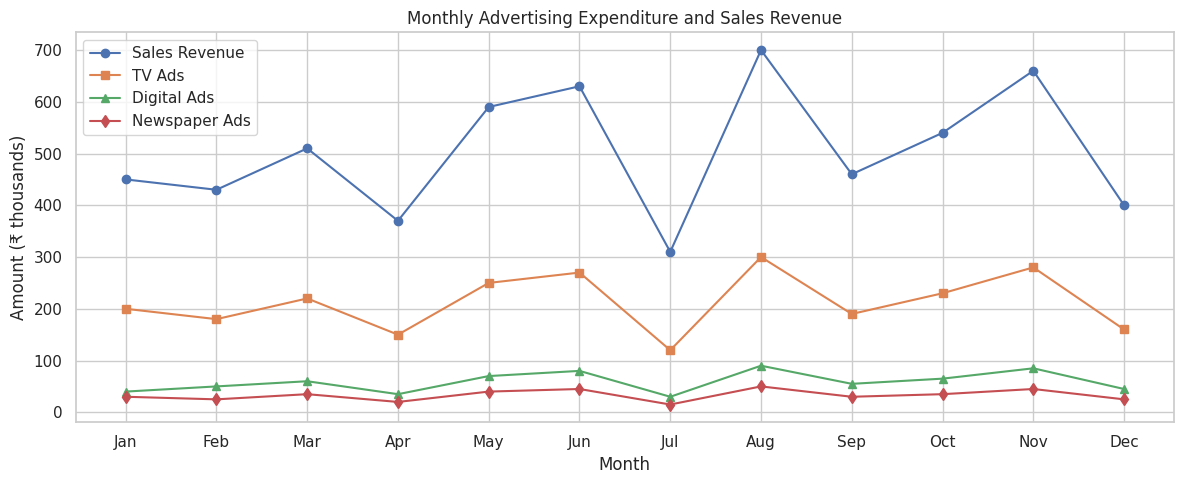

In [4]:
# Advertising expenditure and sales revenue by month
plt.figure(figsize=(12, 5))
plt.plot(df["Month"], df["Sales_Revenue"], marker="o", label="Sales Revenue")
plt.plot(df["Month"], df["TV_Ads"], marker="s", label="TV Ads")
plt.plot(df["Month"], df["Digital_Ads"], marker="^", label="Digital Ads")
plt.plot(df["Month"], df["Newspaper_Ads"], marker="d", label="Newspaper Ads")
plt.title("Monthly Advertising Expenditure and Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Amount (₹ thousands)")
plt.legend()
plt.tight_layout()
plt.show()

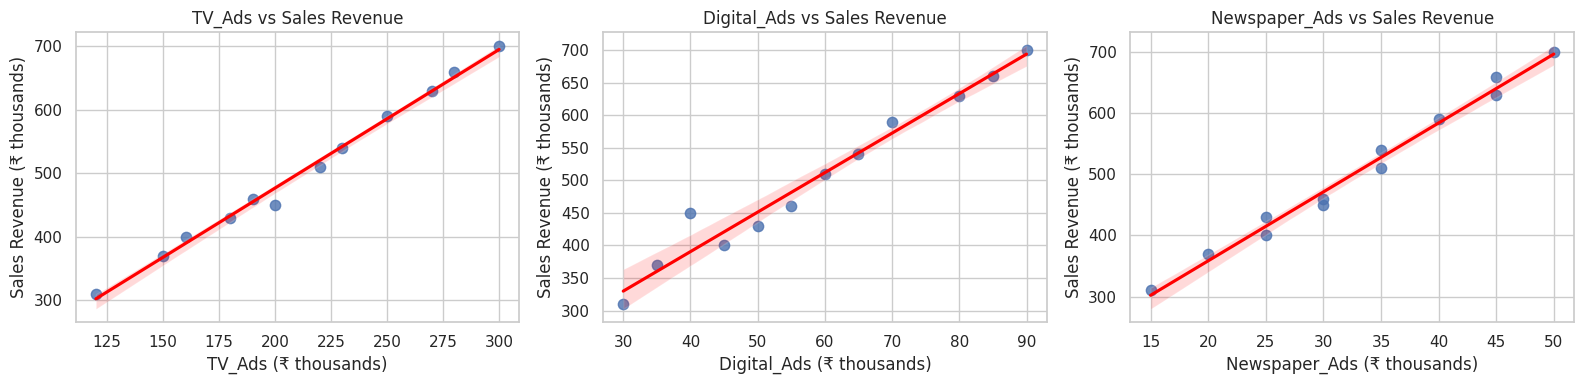

In [5]:
# Scatter plots show the relationship between each advertising channel and sales
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
features = ["TV_Ads", "Digital_Ads", "Newspaper_Ads"]

for ax, feature in zip(axes, features):
    sns.regplot(data=df, x=feature, y="Sales_Revenue", ax=ax,
                scatter_kws={"s": 55}, line_kws={"color": "red"})
    ax.set_title(f"{feature} vs Sales Revenue")
    ax.set_xlabel(f"{feature} (₹ thousands)")
    ax.set_ylabel("Sales Revenue (₹ thousands)")

plt.tight_layout()
plt.show()

## 5. Create a correlation heatmap

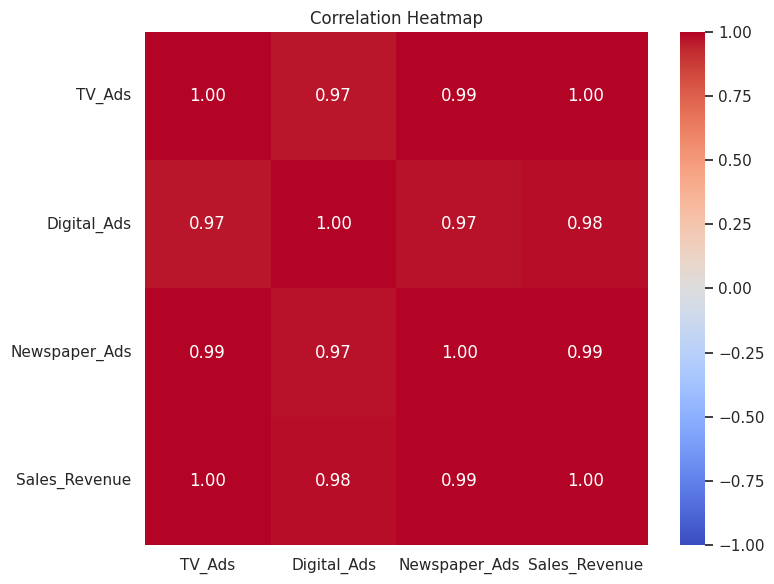

Correlation of each advertising channel with sales:


TV_Ads           0.996461
Newspaper_Ads    0.993195
Digital_Ads      0.982326
Name: Sales_Revenue, dtype: float64

In [6]:
correlation = df[["TV_Ads", "Digital_Ads", "Newspaper_Ads", "Sales_Revenue"]].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

print("Correlation of each advertising channel with sales:")
display(correlation["Sales_Revenue"].drop("Sales_Revenue").sort_values(ascending=False))

## 6. Define independent and dependent variables

- `X` contains the three independent variables: TV Ads, Digital Ads, and Newspaper Ads.
- `y` contains the dependent variable: Sales Revenue.

In [7]:
X = df[["TV_Ads", "Digital_Ads", "Newspaper_Ads"]]
y = df["Sales_Revenue"]

print("Independent variables (X):")
display(X.head())

print("Dependent variable (y):")
display(y.head())

Independent variables (X):


,TV_Ads,Digital_Ads,Newspaper_Ads
0,200,40,30
1,180,50,25
2,220,60,35
3,150,35,20
4,250,70,40


Dependent variable (y):


0    450
1    430
2    510
3    370
4    590
Name: Sales_Revenue, dtype: int64

## 7. Split the dataset into training and testing sets
We use 75% of the observations for training and 25% for testing. `random_state=42` makes the split reproducible.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training feature shape: (9, 3)
Testing feature shape: (3, 3)
Training target shape: (9,)
Testing target shape: (3,)


## 8. Train the Multiple Linear Regression model

In [9]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Multiple Linear Regression model trained successfully!")

Multiple Linear Regression model trained successfully!


## 9. Display regression coefficients and intercept
The fitted equation is: **Sales Revenue = intercept + b₁(TV Ads) + b₂(Digital Ads) + b₃(Newspaper Ads)**.

In [10]:
coefficients = pd.DataFrame({
    "Advertising Channel": X.columns,
    "Coefficient": model.coef_
})

print(f"Intercept: {model.intercept_:.4f}")
display(coefficients)

print(
    f"\\nEquation: Sales Revenue = {model.intercept_:.4f}"
    f" + ({model.coef_[0]:.4f} × TV Ads)"
    f" + ({model.coef_[1]:.4f} × Digital Ads)"
    f" + ({model.coef_[2]:.4f} × Newspaper Ads)"
)

Intercept: 66.6689


,Advertising Channel,Coefficient
0,TV_Ads,1.636608
1,Digital_Ads,0.948856
2,Newspaper_Ads,1.052490


\nEquation: Sales Revenue = 66.6689 + (1.6366 × TV Ads) + (0.9489 × Digital Ads) + (1.0525 × Newspaper Ads)


## 10. Evaluate the model using MAE, MSE, RMSE, and R²

In [11]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

metrics = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R² Score"],
    "Value": [mae, mse, rmse, r2]
})

display(metrics)

print("Interpretation:")
print(f"On this test split, predictions differ from actual sales by about {mae:.2f} ₹ thousand on average (MAE).")
print(f"The R² score is {r2:.4f}. This describes fit on this small held-out test set, not guaranteed future performance.")

,Metric,Value
0,MAE,7.395693
1,MSE,78.423368
2,RMSE,8.855697
3,R² Score,0.989402


Interpretation:
On this test split, predictions differ from actual sales by about 7.40 ₹ thousand on average (MAE).
The R² score is 0.9894. This describes fit on this small held-out test set, not guaranteed future performance.


## 11. Plot actual sales versus predicted sales

,Actual Sales Revenue,Predicted Sales Revenue
0,450,463.519515
9,540,541.601615
10,660,652.934051


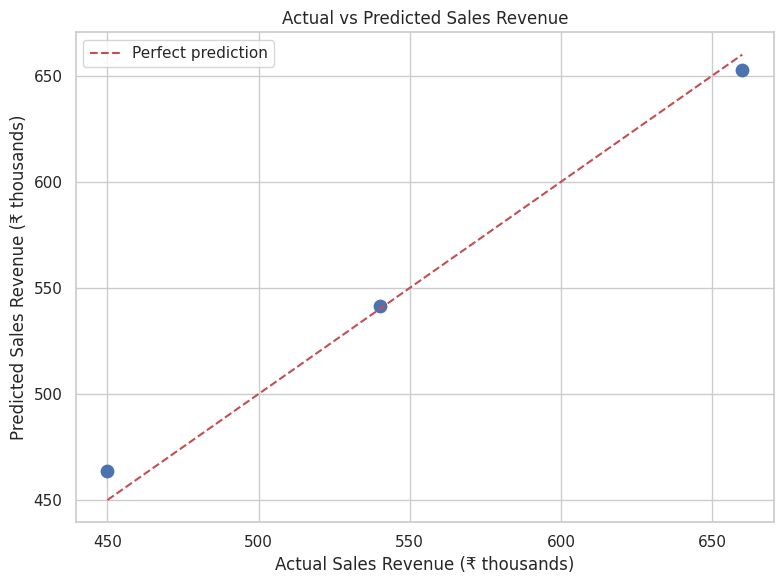

In [12]:
results = pd.DataFrame({
    "Actual Sales Revenue": y_test.values,
    "Predicted Sales Revenue": y_pred
}, index=y_test.index).sort_index()

display(results)

plt.figure(figsize=(8, 6))
plt.scatter(results["Actual Sales Revenue"], results["Predicted Sales Revenue"], s=80)

low = min(results.min())
high = max(results.max())
plt.plot([low, high], [low, high], "r--", label="Perfect prediction")

plt.title("Actual vs Predicted Sales Revenue")
plt.xlabel("Actual Sales Revenue (₹ thousands)")
plt.ylabel("Predicted Sales Revenue (₹ thousands)")
plt.legend()
plt.tight_layout()
plt.show()

## 12. Identify the advertising channel with the strongest relationship with sales

In [13]:
# Correlation measures pairwise linear association.
sales_correlations = df[["TV_Ads", "Digital_Ads", "Newspaper_Ads", "Sales_Revenue"]].corr()["Sales_Revenue"].drop("Sales_Revenue")
strongest_correlation_channel = sales_correlations.abs().idxmax()

# Regression coefficients estimate each feature's contribution while holding the others fixed.
# Since all features use ₹ thousands, their coefficient magnitudes are comparable in this dataset.
strongest_coefficient_channel = pd.Series(model.coef_, index=X.columns).abs().idxmax()

print("Correlation with sales:")
display(sales_correlations.sort_values(key=lambda s: s.abs(), ascending=False))
print("Strongest pairwise linear relationship:", strongest_correlation_channel)
print("Largest absolute fitted regression coefficient:", strongest_coefficient_channel)

Correlation with sales:


TV_Ads           0.996461
Newspaper_Ads    0.993195
Digital_Ads      0.982326
Name: Sales_Revenue, dtype: float64

Strongest pairwise linear relationship: TV_Ads
Largest absolute fitted regression coefficient: TV_Ads


## 13. Challenge question: Predict sales for a new advertising budget

The company plans to spend:
- TV Ads: ₹240,000
- Digital Ads: ₹75,000
- Newspaper Ads: ₹40,000

Because the dataset values are in ₹ thousands, enter these as **240, 75, and 40**.

In [14]:
new_ad_budget = pd.DataFrame({
    "TV_Ads": [240],
    "Digital_Ads": [75],
    "Newspaper_Ads": [40]
})

predicted_sales_thousands = model.predict(new_ad_budget)[0]
predicted_sales_rupees = predicted_sales_thousands * 1000

print(f"Predicted monthly sales revenue: ₹{predicted_sales_thousands:.2f} thousand")
print(f"Predicted monthly sales revenue: ₹{predicted_sales_rupees:,.2f}")

Predicted monthly sales revenue: ₹572.72 thousand
Predicted monthly sales revenue: ₹572,718.71


## 14. Conclusion

This notebook completed the Multiple Linear Regression workflow:
1. Loaded the sample sales dataset into Pandas.
2. Inspected the data and checked for missing values.
3. Visualized advertising expenditure and sales.
4. Examined correlations using a heatmap.
5. Defined independent and dependent variables.
6. Split the data into training and testing sets.
7. Trained a Multiple Linear Regression model.
8. Examined model coefficients and intercept.
9. Evaluated predictions using MAE, MSE, RMSE, and R².
10. Compared actual and predicted sales.
11. Identified the strongest channel by correlation and by fitted coefficient.
12. Predicted sales for the challenge advertising budget.

**Important limitation:** There are only 12 monthly records, so the test set contains just 3 observations. The evaluation metrics and challenge prediction are illustrative. A real business model should use substantially more historical data, ideally covering multiple seasonal cycles, and should be validated on later months.